--- Đang nạp và xử lý dữ liệu Laptop từ Kaggle ---
-> Đã nạp thành công 1303 dòng dữ liệu thực tế!


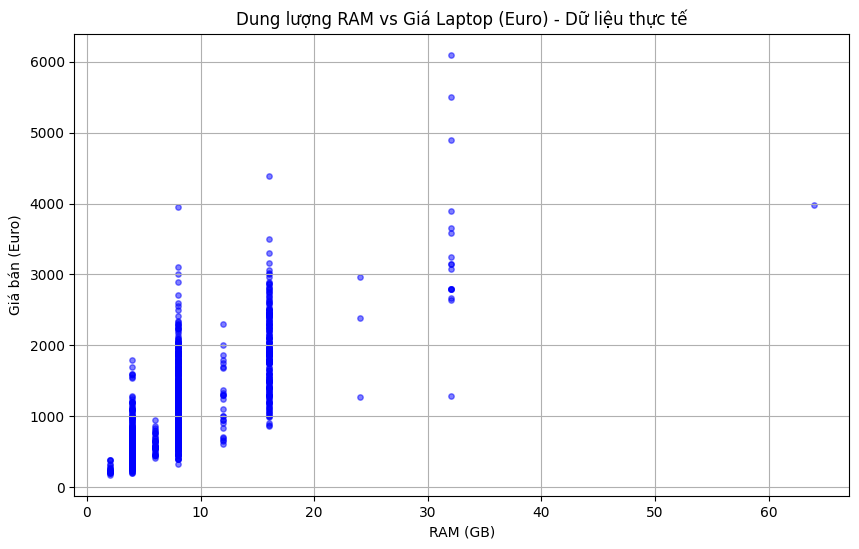


--- KẾT QUẢ NGHIỆM PHÂN TÍCH (NORMAL EQUATION) ---
Hệ số chặn (theta_0): 0.0000
Độ dốc (theta_1)  : 0.7430
Ghi chú: Bộ tham số này là mốc chuẩn để kiểm tra thuật toán Gradient Descent.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# TASK 1 & 2 (TV1): TẢI DỮ LIỆU THẬT VÀ LÀM SẠCH (DATA PREP)
# ==========================================
print("--- Đang nạp và xử lý dữ liệu Laptop từ Kaggle ---")

# 1. Đọc file CSV thật (đang nằm cùng thư mục)
df = pd.read_csv('laptop_price.csv', encoding='latin-1')

# 2. LÀM SẠCH DỮ LIỆU: Xóa chữ 'GB' trong cột Ram và ép về kiểu số nguyên (int)
df['Ram'] = df['Ram'].str.replace('GB', '').astype(int)

# 3. Trích xuất mảng X (RAM) và y (Giá bằng Euro)
X_raw = df['Ram'].values.reshape(-1, 1)
y_raw = df['Price_euros'].values.reshape(-1, 1)

print(f"-> Đã nạp thành công {len(df)} dòng dữ liệu thực tế!")

# --- Khám phá dữ liệu (EDA) ---
plt.figure(figsize=(10, 6))
plt.scatter(X_raw, y_raw, alpha=0.5, color='blue', s=15)
plt.title("Dung lượng RAM vs Giá Laptop (Euro) - Dữ liệu thực tế")
plt.xlabel("RAM (GB)")
plt.ylabel("Giá bán (Euro)")
plt.grid(True)
plt.show()

# ==========================================
# CHUẨN HÓA Z-SCORE VÀ TÍNH NORMAL EQUATION
# ==========================================
X_mean, X_std = np.mean(X_raw), np.std(X_raw)
y_mean, y_std = np.mean(y_raw), np.std(y_raw)

X_scaled = (X_raw - X_mean) / X_std
y_scaled = (y_raw - y_mean) / y_std

# Tính Normal Equation
X_b = np.c_[np.ones((len(X_scaled), 1)), X_scaled]
theta_analytical = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y_scaled)

print("\n--- KẾT QUẢ NGHIỆM PHÂN TÍCH (NORMAL EQUATION) ---")
print(f"Hệ số chặn (theta_0): {theta_analytical[0][0]:.4f}")
print(f"Độ dốc (theta_1)  : {theta_analytical[1][0]:.4f}")
print("Ghi chú: Bộ tham số này là mốc chuẩn để kiểm tra thuật toán Gradient Descent.")

In [5]:
# ==========================================
# TASK 3 & 4 (TV2): GRADIENT DESCENT VÀ COST FUNCTION
# ==========================================
print("\n--- BẮT ĐẦU HUẤN LUYỆN BẰNG GRADIENT DESCENT ---")

# 1. Hàm tính Cost Function (MSE)
def compute_cost(X, y, theta):
    m = len(y)
    predictions = X.dot(theta)
    cost = (1 / (2 * m)) * np.sum(np.square(predictions - y))
    return cost

# 2. Thuật toán Gradient Descent
def gradient_descent(X, y, theta, learning_rate, epochs):
    m = len(y)
    cost_history = np.zeros(epochs)
    theta_history = np.zeros((epochs, 2)) 

    for i in range(epochs):
        # Tính dự đoán và chênh lệch
        predictions = X.dot(theta)
        
        # Cập nhật đạo hàm và tham số
        gradients = (1 / m) * X.T.dot(predictions - y)
        theta = theta - learning_rate * gradients
        
        # Lưu lịch sử
        cost_history[i] = compute_cost(X, y, theta)
        theta_history[i, :] = theta.T
        
        if i % 100 == 0:
            print(f"Epoch {i}: Cost = {cost_history[i]:.4f}")
            
    return theta, cost_history, theta_history

# 3. Thực thi thuật toán
m = len(X_scaled)
X_b = np.c_[np.ones((m, 1)), X_scaled]
np.random.seed(42)
initial_theta = np.random.randn(2, 1)

alpha = 0.1     # Learning rate 
epochs = 1000   # Số vòng lặp

theta_gd, cost_history, theta_history = gradient_descent(X_b, y_scaled, initial_theta, alpha, epochs)

print("\n--- KẾT QUẢ GRADIENT DESCENT ---")
print(f"Hệ số chặn (theta_0): {theta_gd[0][0]:.4f}")
print(f"Độ dốc (theta_1)  : {theta_gd[1][0]:.4f}")


--- BẮT ĐẦU HUẤN LUYỆN BẰNG GRADIENT DESCENT ---
Epoch 0: Cost = 0.6384
Epoch 100: Cost = 0.2240
Epoch 200: Cost = 0.2240
Epoch 300: Cost = 0.2240
Epoch 400: Cost = 0.2240
Epoch 500: Cost = 0.2240
Epoch 600: Cost = 0.2240
Epoch 700: Cost = 0.2240
Epoch 800: Cost = 0.2240
Epoch 900: Cost = 0.2240

--- KẾT QUẢ GRADIENT DESCENT ---
Hệ số chặn (theta_0): 0.0000
Độ dốc (theta_1)  : 0.7430


In [ ]:
# ==========================================
# TASK 5 (TV3): TRỰC QUAN HÓA 3D COST SURFACE VÀ CONTOUR PLOT
# ==========================================
from mpl_toolkits.mplot3d import Axes3D

print("\n--- VẼ BIỂU ĐỒ 3D COST SURFACE VÀ ĐƯỜNG ĐI CỦA THUẬT TOÁN ---")

def compute_cost_surface(X, y, theta0_range, theta1_range):
    J_vals = np.zeros((len(theta0_range), len(theta1_range)))
    for i, t0 in enumerate(theta0_range):
        for j, t1 in enumerate(theta1_range):
            t = np.array([[t0], [t1]])
            J_vals[i, j] = compute_cost(X, y, t)
    return J_vals

# Lập lưới tham số xung quanh điểm tối ưu
theta0_vals = np.linspace(-2, 2, 100)
theta1_vals = np.linspace(-2, 2, 100)
J_vals = compute_cost_surface(X_b, y_scaled, theta0_vals, theta1_vals)
T0, T1 = np.meshgrid(theta0_vals, theta1_vals)

# Khởi tạo khung vẽ chứa 2 biểu đồ
fig = plt.figure(figsize=(14, 6))

# Đồ thị 1: 3D Cost Surface
ax1 = fig.add_subplot(121, projection='3d')
surf = ax1.plot_surface(T0, T1, J_vals.T, cmap='viridis', alpha=0.8)
ax1.set_xlabel('Hệ số chặn (Theta 0)')
ax1.set_ylabel('Độ dốc (Theta 1)')
ax1.set_zlabel('Sai số (Cost)')
ax1.set_title('3D Cost Surface')

# Đồ thị 2: Contour Plot
ax2 = fig.add_subplot(122)
contour = ax2.contour(T0, T1, J_vals.T, np.logspace(-2, 3, 20), cmap='viridis')
# Vẽ đường đi hội tụ của Gradient Descent
ax2.plot(theta_history[:, 0], theta_history[:, 1], 'r-x', markersize=3, linewidth=1, label='Đường đi GD')
# Đánh dấu điểm cực tiểu (nghiệm Normal Equation)
ax2.plot(theta_analytical[0][0], theta_analytical[1][0], 'ro', label='Điểm tối ưu (Normal Eq)')

ax2.set_xlabel('Hệ số chặn (Theta 0)')
ax2.set_ylabel('Độ dốc (Theta 1)')
ax2.set_title('Bản đồ đường đồng mức & Quá trình hội tụ')
ax2.legend()

plt.tight_layout()
plt.show()


--- CHUẨN BỊ VẼ BIỂU ĐỒ 3D COST SURFACE ---
